# 第 16—30 图：Jupyter 代码复刻

从 `data/第二章 图表(后15).xlsx` 读取数据，使用 pandas、NumPy、Matplotlib 绘制后 15 张图。此项目独立运行，只需要随附的一份 Excel。

## 运行

保留完整目录结构，在 Jupyter 中选择 Python 3 内核，先执行公共设置，再运行任意单图单元格，或运行全部单元格。图片显示在单元格下方，并保存到 `outputs/charts/`。缺少依赖时运行：

```python
%pip install numpy pandas matplotlib openpyxl
```

字体优先使用微软雅黑，没有时使用 `assets/fonts` 中的思源黑体。第 21 图对应原表重复编号为 20 的 PPT 示例。其占比合计 98.3%，代码保留空白角度，不自动归一化。

**复刻边界：**字体、换行、抗锯齿、部分半径层级和标签位置可能与办公软件略有差异，不能保证逐像素相同。修改数据时请同步核对原模板保留的标题、说明和固定坐标轴上限。

## 0. 公共设置

将图号 16—30 映射到后 15 图 Excel 的第 1—15 个工作表。支持从项目根目录或 notebooks 目录启动。

In [1]:
%matplotlib inline
from pathlib import Path
from io import BytesIO
import math
import zipfile
import xml.etree.ElementTree as ET
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import font_manager, colors
from matplotlib.font_manager import FontProperties
from matplotlib.patches import Rectangle, FancyBboxPatch, PathPatch, Circle, Wedge
from matplotlib.path import Path as MplPath
from matplotlib.ticker import FuncFormatter

# 从脚本目录或 Notebook 工作目录向上定位项目，支持不同启动目录。
def find_project_root():
    candidates = [Path.cwd()]
    if '__file__' in globals():
        candidates.insert(0, Path(__file__).resolve().parent)
    for start in candidates:
        for candidate in (start, *start.parents):
            if (candidate / 'data' / '第二章 图表(后15).xlsx').is_file():
                return candidate
    raise FileNotFoundError('找不到项目 data 目录。请保留完整项目结构，并从项目根目录或 notebooks 目录运行。')

BASE_DIR = find_project_root()
EXCEL_FILE = BASE_DIR / 'data' / '第二章 图表(后15).xlsx'
OUT_DIR = BASE_DIR / 'outputs' / 'charts'
OUT_DIR.mkdir(parents=True, exist_ok=True)
if not EXCEL_FILE.exists():
    raise FileNotFoundError(f'未找到 {EXCEL_FILE.name}。请将 Excel 放在项目 data 目录，或修改 EXCEL_FILE。')

for font_file in (BASE_DIR / 'assets' / 'fonts').glob('*.otf'):
    font_manager.fontManager.addfont(str(font_file))
available_fonts = {f.name for f in font_manager.fontManager.ttflist}
FONT = next((s for s in ['Microsoft YaHei', '微软雅黑', 'Noto Sans CJK SC', 'SimHei', 'PingFang SC']
             if s in available_fonts), 'DejaVu Sans')
if FONT == 'DejaVu Sans':
    raise RuntimeError('缺少中文字体。请保留配套 assets/fonts 文件夹，或安装微软雅黑/黑体后重启内核。')
plt.rcParams.update({'font.family': FONT, 'axes.unicode_minus': False,
                     'figure.dpi': 110, 'savefig.dpi': 180,
                     'svg.fonttype': 'path', 'axes.linewidth': 0.6})
BG, WHITE = '#1A1E43', '#F2F2F2'
BLUE, PINK, LIGHT_BLUE = '#0070C0', '#E74E69', '#82ADD7'
NS = {'c': 'http://schemas.openxmlformats.org/drawingml/2006/chart',
      'a': 'http://schemas.openxmlformats.org/drawingml/2006/main',
      'd': 'http://schemas.openxmlformats.org/drawingml/2006/chartDrawing'}
SHEET_NAMES = dict(enumerate(pd.ExcelFile(EXCEL_FILE, engine='openpyxl').sheet_names, start=16))


def read_table(number, usecols, nrows, header=1):
    """按图号 16—30 直接映射后 15 图 Excel 的工作表位置。"""
    df = pd.read_excel(EXCEL_FILE, sheet_name=SHEET_NAMES[number],
                       usecols=usecols, header=header, nrows=nrows,
                       engine='openpyxl')
    df.columns = [str(c).strip() for c in df.columns]
    if df.iloc[:, 0].isna().any():
        raise ValueError(f'{SHEET_NAMES[number]} 的数据区域含空白分类，请检查原表。')
    return df


def numeric(df, column):
    return pd.to_numeric(df[column], errors='raise').to_numpy(dtype=float)


def xml_color(element, default=WHITE):
    if element is None:
        return default
    rgb = element.find('.//a:srgbClr', NS)
    scheme = element.find('.//a:schemeClr', NS)
    if rgb is not None:
        value, node = '#' + rgb.get('val'), rgb
    elif scheme is not None:
        palette = {'bg1': '#FFFFFF', 'lt1': '#FFFFFF', 'dk1': '#000000',
                   'tx1': '#000000', 'accent1': BLUE, 'accent2': '#ED7D31'}
        value, node = palette.get(scheme.get('val'), default), scheme
    else:
        return default
    rgb_array = np.array(colors.to_rgb(value))
    mod, off, alpha = 1., 0., 1.
    for child in node:
        key = child.tag.split('}')[-1]
        if key == 'lumMod': mod = int(child.get('val')) / 100000
        elif key == 'lumOff': off = int(child.get('val')) / 100000
        elif key == 'alpha': alpha = int(child.get('val')) / 100000
    return (*np.clip(rgb_array * mod + off, 0, 1), alpha)


def template_xml(number):
    """只读取后 15 图工作簿内的矢量样式和文本，不粘贴截图。"""
    chart_number = {16:1,17:2,18:3,19:4,20:5,21:6,22:7,23:8,24:10,25:12,
                    26:13,27:14,28:15,29:16,30:17}[number]
    with zipfile.ZipFile(EXCEL_FILE) as archive:
        chart = ET.fromstring(archive.read(f'xl/charts/chart{chart_number}.xml'))
        rels = ET.fromstring(archive.read(f'xl/charts/_rels/chart{chart_number}.xml.rels'))
        shape_ref = chart.find('c:userShapes', NS)
        shape_root = None
        if shape_ref is not None:
            rid = shape_ref.get('{http://schemas.openxmlformats.org/officeDocument/2006/relationships}id')
            rel = next(r for r in rels if r.get('Id') == rid)
            name = Path(rel.get('Target')).name
            shape_root = ET.fromstring(archive.read('xl/drawings/' + name))
    return chart, shape_root


# 保留各示例画布的长宽比例；绘图区位置直接读取 Excel 的 manualLayout。
ASPECTS = {16:865/604,17:865/578,18:865/606,19:866/607,20:869/610,
           21:837/586,22:865/607,23:865/578,24:432/285,25:481/316,
           26:864/580,27:865/607,28:878/602,29:878/578,30:866/579}


def canvas(number):
    fig = plt.figure(figsize=(6, 6/ASPECTS[number]), facecolor=BG)
    chart, shape_root = template_xml(number)
    if chart is not None:
        layout = chart.find('c:chart/c:plotArea/c:layout/c:manualLayout', NS)
        if layout is not None:
            d = {e.tag.split('}')[-1]: e.get('val') for e in layout}
            x, top, w, h = (float(d[k]) for k in ('x', 'y', 'w', 'h'))
            bounds = [x, 1-top-h, w, h]
        else:
            bounds = [.25, .16, .50, .60]
    else:
        bounds = [.12, .22, .76, .43]
    ax = fig.add_axes(bounds, facecolor=BG)
    for sp in ax.spines.values(): sp.set_visible(False)
    ax.tick_params(colors=WHITE, labelsize=9, length=0, pad=3)
    ax.set_axisbelow(True)
    return fig, ax, shape_root


def text_width(fig, text, size, weight='normal'):
    prop = FontProperties(family=FONT, size=size, weight=weight)
    return fig.canvas.get_renderer().get_text_width_height_descent(text, prop, False)[0] / fig.dpi


def wrap_text(fig, text, size, width, weight='normal'):
    lines, line = [], ''
    for ch in text:
        if ch == '\n' or (line and text_width(fig, line + ch, size, weight) > width):
            lines.append(line)
            line = '' if ch == '\n' else ch
        else:
            line += ch
    if line: lines.append(line)
    return lines or ['']


def template_text(fig, root, replacements=None, skip_text=(), skip_exact=()):
    """读取原图文本框的坐标、字号、粗细、文字颜色和段间距。"""
    if root is None: return
    replacements = replacements or {}
    fw, fh = fig.get_size_inches()
    for anchor in root:
        shape = anchor.find('d:sp', NS)
        if shape is None: continue
        body = shape.find('d:txBody', NS)
        if body is None: continue
        paragraphs = body.findall('a:p', NS)
        if not any(p.find('.//a:t', NS) is not None for p in paragraphs): continue
        actual_text = ''.join(t.text or '' for t in body.findall('.//a:t', NS))
        if actual_text in skip_exact or any(t in actual_text for t in skip_text): continue
        origin, end = anchor.find('d:from', NS), anchor.find('d:to', NS)
        if origin is None or end is None: continue
        x0, top = float(origin.find('d:x', NS).text), float(origin.find('d:y', NS).text)
        x1, bot = float(end.find('d:x', NS).text), float(end.find('d:y', NS).text)
        bp = body.find('a:bodyPr', NS)
        li = float(bp.get('lIns', '91440')) / 914400 if bp is not None else .1
        ti = float(bp.get('tIns', '45720')) / 914400 if bp is not None else .05
        ri = float(bp.get('rIns', '91440')) / 914400 if bp is not None else .1
        vcenter = bp is not None and bp.get('anchor') == 'ctr'
        cursor = top + ti/fh
        for para in paragraphs:
            text = ''.join(t.text or '' for t in para.findall('.//a:t', NS))
            for old, new in replacements.items(): text = text.replace(old, new)
            if not text: continue
            run_props = para.find('a:r/a:rPr', NS)
            if run_props is None: run_props = para.find('a:endParaRPr', NS)
            size = float(run_props.get('sz', '1100'))/100 if run_props is not None else 11
            weight = 'bold' if run_props is not None and run_props.get('b') == '1' else 'normal'
            color = xml_color(run_props)
            pp = para.find('a:pPr', NS)
            center = pp is not None and pp.get('algn') == 'ctr'
            lines = wrap_text(fig, text, size, max(.3, (x1-x0)*fw-li-ri), weight)
            spacing = para.find('a:pPr/a:lnSpc/a:spcPts', NS)
            leading = float(spacing.get('val'))/100 if spacing is not None else size*1.3
            xpos = (x0+x1)/2 if center else x0+li/fw
            ypos = (top+bot)/2 if vcenter and len(paragraphs)==1 else cursor
            fig.text(xpos, 1-ypos, '\n'.join(lines), fontsize=size, color=color,
                     weight=weight, ha='center' if center else 'left',
                     va='center' if vcenter and len(paragraphs)==1 else 'top',
                     linespacing=leading/size, zorder=20)
            cursor += max(leading, size*1.15)*len(lines)/72/fh


def category_axis(ax, labels, ymax, step=None, grid=True, ylabels=True, baseline=False):
    ax.set_xlim(-.5, len(labels)-.5)
    ax.set_xticks(np.arange(len(labels)), labels)
    ax.set_ylim(0, ymax)
    if step is not None: ax.set_yticks(np.arange(0, ymax + step*.01, step))
    if not ylabels: ax.set_yticks([])
    if grid: ax.yaxis.grid(True, color=WHITE, alpha=.20, lw=.5, ls=(0,(6,3)))
    if baseline:
        ax.spines['bottom'].set_visible(True)
        ax.spines['bottom'].set_color((1,1,1,.35))


def gradient_rect(ax, x, y, w, h, bottom, top, rounded=False):
    ramp = np.linspace(0, 1, 320)[:, None, None]
    c0, c1 = np.array(colors.to_rgba(bottom)), np.array(colors.to_rgba(top))
    img = ax.imshow(c0[None,None,:]*(1-ramp)+c1[None,None,:]*ramp,
                    extent=(x,x+w,y,y+h), origin='lower', aspect='auto',
                    interpolation='bicubic', zorder=3)
    if rounded:
        # 使用显示坐标计算圆角，避免横纵轴量纲不同造成圆角失真。
        p0, p1 = ax.transData.transform((0,0)), ax.transData.transform((1,1))
        rx = w/2
        ry = min(h/2, rx*abs((p1[0]-p0[0])/(p1[1]-p0[1])))
        k = .55228475
        verts=[(x+rx,y),(x+w-rx,y),(x+w-rx+k*rx,y),(x+w,y+ry-k*ry),(x+w,y+ry),
               (x+w,y+h-ry),(x+w,y+h-ry+k*ry),(x+w-rx+k*rx,y+h),(x+w-rx,y+h),
               (x+rx,y+h),(x+rx-k*rx,y+h),(x,y+h-ry+k*ry),(x,y+h-ry),
               (x,y+ry),(x,y+ry-k*ry),(x+rx-k*rx,y),(x+rx,y),(x+rx,y)]
        codes=[MplPath.MOVETO,MplPath.LINETO]+[MplPath.CURVE4]*3+[MplPath.LINETO]+[MplPath.CURVE4]*3+[MplPath.LINETO]+[MplPath.CURVE4]*3+[MplPath.LINETO]+[MplPath.CURVE4]*3+[MplPath.CLOSEPOLY]
        clip=PathPatch(MplPath(verts,codes),facecolor='none',edgecolor='none')
        ax.add_patch(clip); img.set_clip_path(clip)
    return img


def value_labels(ax, x, y, color=WHITE, size=9, offset=3, **kwargs):
    for a,b in zip(x,y):
        ax.annotate(f'{b:g}', (a,b), xytext=(0,offset), textcoords='offset points',
                    ha='center', va='bottom', color=color, fontsize=size, zorder=8, **kwargs)


def finish(fig, number, name, show=True):
    # 不使用 tight_layout/bbox_inches='tight'，保留模板边距和原始画布比例。
    path = OUT_DIR / f'{number:02d}_{name}.png'
    fig.savefig(path, dpi=180, facecolor=BG, edgecolor=BG)
    if show: plt.show()
    return fig


def smooth_curve(x, y, samples=50):
    """保形三次 Hermite 插值，经过所有原始点，避免平滑曲线产生虚假的负数。"""
    x, y = np.asarray(x,float), np.asarray(y,float)
    slopes = np.diff(y)/np.diff(x)
    tangents = np.zeros(len(y)); tangents[0],tangents[-1]=slopes[0],slopes[-1]
    for j in range(1,len(y)-1):
        if slopes[j-1]*slopes[j] > 0:
            tangents[j] = 2/(1/slopes[j-1]+1/slopes[j])
    xx, yy = [], []
    for j in range(len(x)-1):
        t=np.linspace(0,1,samples,endpoint=(j==len(x)-2)); h=x[j+1]-x[j]
        yy.extend((2*t**3-3*t**2+1)*y[j]+(t**3-2*t**2+t)*h*tangents[j]
                  +(-2*t**3+3*t**2)*y[j+1]+(t**3-t**2)*h*tangents[j+1])
        xx.extend(x[j]+t*h)
    return np.array(xx),np.array(yy)

print(f'已读取 {len(SHEET_NAMES)} 个工作表；中文字体：{FONT}；图片输出：{OUT_DIR.name}')

from matplotlib.lines import Line2D


def check_rates(values):
    if not np.isfinite(values).all() or ((values < 0) | (values > 1)).any():
        raise ValueError('占比/完成率必须为 0 到 1 之间的有效数值。')


def round_axes(ax):
    ax.set_aspect('equal')
    ax.set_xlim(-1.04, 1.04)
    ax.set_ylim(-1.04, 1.04)
    ax.axis('off')


def rose(ax, labels, values, palette, hole=0, normalize=True):
    """按原比例决定扇区角度和半径；不把扇区重画成等角度。"""
    check_rates(values)
    if values.sum() <= 0:
        raise ValueError('占比合计必须大于零。')
    round_axes(ax)
    angles = values / values.sum() if normalize else values
    middles = 90 - (np.cumsum(angles)-angles/2)*360
    left_indices = [i for i,a in enumerate(middles) if np.cos(np.deg2rad(a)) < 0]
    left_positions = dict(zip(left_indices, np.linspace(-.88,.94,len(left_indices))))
    start = 90.
    for index,(label, value, fraction, color) in enumerate(zip(labels, values, angles, palette)):
        end = start - fraction * 360
        radius = hole + (1-hole) * value/values.max()
        ax.add_patch(Wedge((0,0),radius,end,start,width=radius-hole if hole else None,
                           facecolor=color,edgecolor=BG,lw=.35))
        middle=np.deg2rad((start+end)/2)
        # 使用两段引导线，把标签放在扇区外，避免遮挡扇区。
        side=1 if np.cos(middle)>=0 else -1
        sy=radius*np.sin(middle)
        label_y=np.clip(sy*1.15,-1.04,1.04)
        if side<0:
            label_y=left_positions[index]
        x0,y0=radius*np.cos(middle),radius*np.sin(middle)
        x1,y1=side*1.17,label_y
        x2=side*1.64
        ax.plot([x0,x1,x2],[y0,y1,y1],color=color,lw=.45,alpha=.9,clip_on=False)
        ax.text((x1+x2)/2,y1+.035,f'{str(label).strip()}\n{value:.1%}',
                ha='center',va='bottom',fontsize=8,color=WHITE,clip_on=False,linespacing=1.15)
        start=end




已读取 15 个工作表；中文字体：Noto Sans CJK SC；图片输出：charts


## 16. 波浪水球图

数据源：后 15 图 Excel 的第 1 个工作表，区域 `B3:C4`（含表头）。

表头在第 3 行，使用 header=2；完成率位于 B4。由完成率计算水位，用正弦波和圆形裁切生成波浪效果。

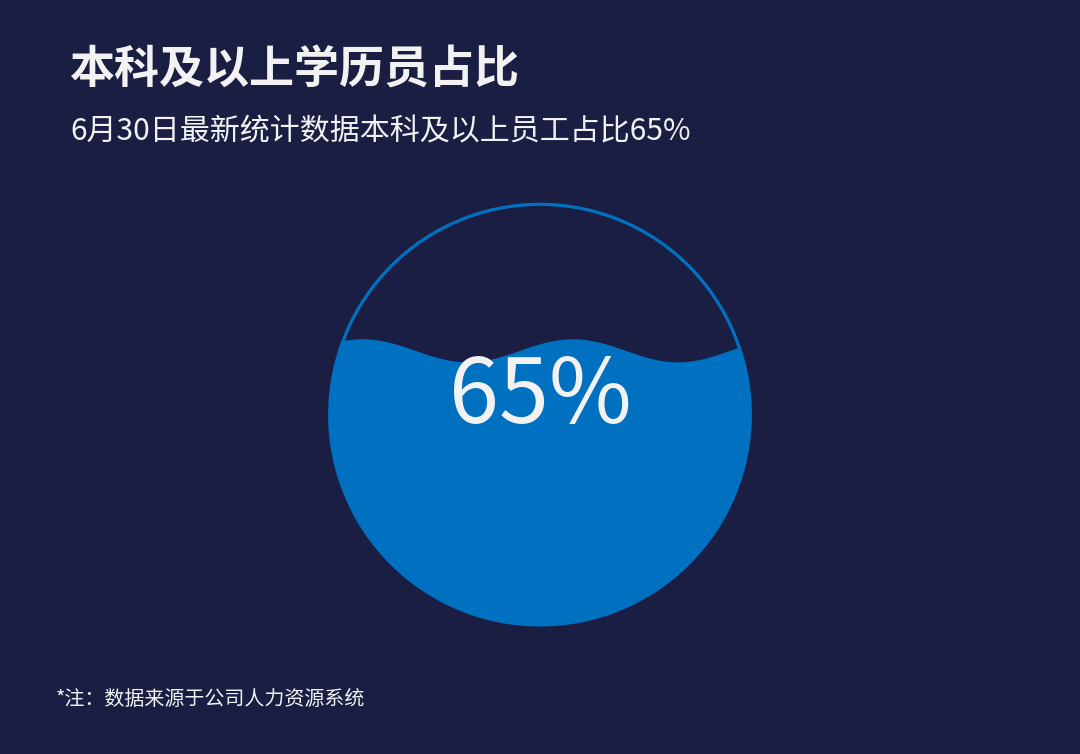

In [2]:
def chart_16(show=True):
    df=read_table(16,'B:C',1,header=2)
    p=float(df.loc[0,'完成率']);check_rates(np.array([p]))
    fig,ax,root=canvas(16)
    ax.set_position([.26,.16,.48,.58]);round_axes(ax)
    boundary=Circle((0,0),1,facecolor='none',edgecolor=BLUE,lw=1.3,zorder=5)
    ax.add_patch(boundary)
    x=np.linspace(-1.1,1.1,800)
    level=2*p-1
    wave=level+.055*np.sin(2*np.pi*(x+1)+.6)
    water=ax.fill_between(x,-1.1,wave,color=BLUE,zorder=3)
    water.set_clip_path(boundary)
    ax.text(0,.08,f'{p:.0%}',ha='center',va='center',color=WHITE,fontsize=36,zorder=8)
    fig.text(.065,.938,'本科及以上学历员占比',fontsize=18,weight='bold',color=WHITE,va='top')
    fig.text(.065,.845,f'6月30日最新统计数据本科及以上员工占比{p:.0%}',fontsize=12,color=WHITE,va='top')
    fig.text(.052,.065,'*注：数据来源于公司人力资源系统',fontsize=8,color=WHITE)
    return finish(fig,16,'波浪水球图',show)

fig=chart_16()
plt.close(fig)

## 17. 玉玦图

数据源：后 15 图 Excel 的第 2 个工作表，区域 `B2:D6`（含表头）。

四圈弧分别读取年龄占比，占位基准为首尾占比之和。内孔采用源 XML 的 35%，扇形弧长按占比计算。

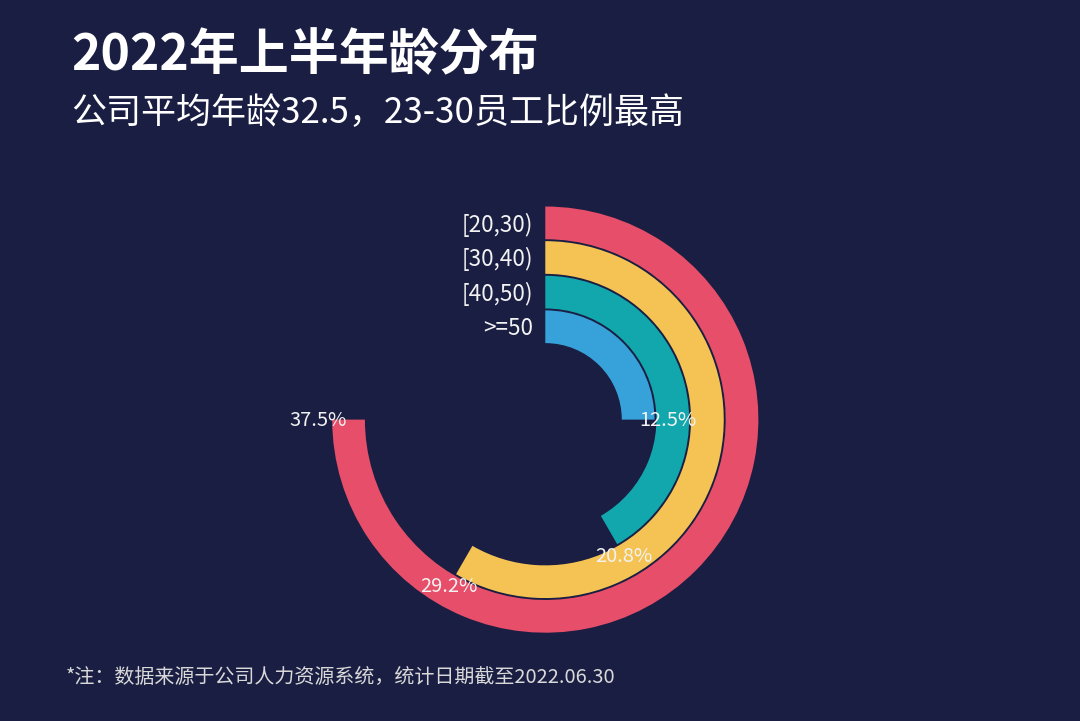

In [3]:
def chart_17(show=True):
    df=read_table(17,'B:D',4)
    p=numeric(df,'占比');check_rates(p)
    total=p[0]+p[-1]  # 原模板：每一圈“占比+占位”均为 50%。
    if total<=0 or np.any(p>total):raise ValueError('占比超过玉玦图的原始比例基准。')
    fig,ax,root=canvas(17);round_axes(ax)
    palette=['#37A2DA','#11A7AD','#F5C353',PINK]
    hole=.35;width=(1-hole)/len(df)
    for i,(label,value,color) in enumerate(zip(df['年龄'],p,palette)):
        radius=hole+(i+1)*width
        theta=90-360*value/total
        ax.add_patch(Wedge((0,0),radius,theta,90,width=width-.009,facecolor=color,edgecolor='none'))
        mid=radius-width/2
        ax.text(-.055,mid,str(label),ha='right',va='center',fontsize=9,color=WHITE)
        ang=np.deg2rad(theta)
        ax.text((radius+.065)*np.cos(ang),(radius+.065)*np.sin(ang),f'{value:.1%}',
                ha='center',va='center',fontsize=8,color=WHITE)
    template_text(fig,root,skip_text=('[20,30)',))
    return finish(fig,17,'玉玦图',show)

fig=chart_17()
plt.close(fig)

## 18. 跑道图

数据源：后 15 图 Excel 的第 3 个工作表，区域 `B2:D8`（含表头）。

六条同心跑道表示六个部门；弧长与人数相关，基准为总人数的一半。内孔沿用源 XML 的 45%。

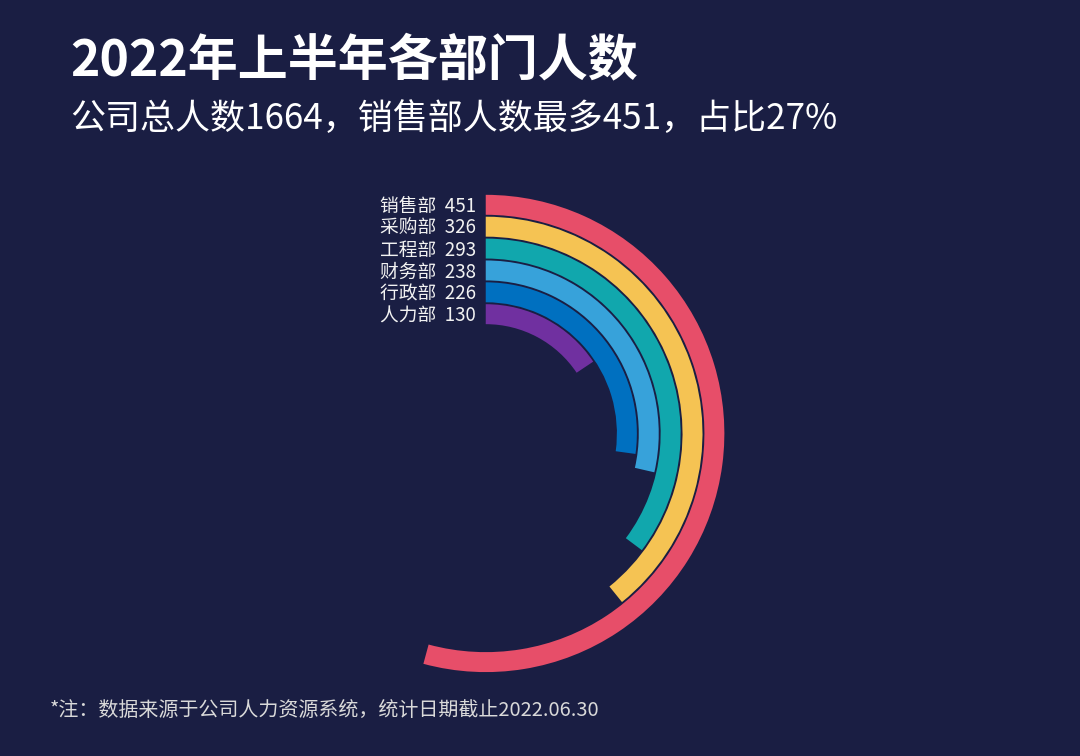

In [4]:
def chart_18(show=True):
    df=read_table(18,'B:D',6)
    y=numeric(df,'人数');total=y.sum()/2
    if total<=0:raise ValueError('部门人数合计必须大于零。')
    fig,ax,root=canvas(18);round_axes(ax)
    palette=['#7030A0',BLUE,'#37A2DA','#11A7AD','#F5C353',PINK]
    hole=.45;width=(1-hole)/len(df)
    for i,(label,value,color) in enumerate(zip(df['部门'],y,palette)):
        radius=hole+(i+1)*width
        ax.add_patch(Wedge((0,0),radius,90-360*value/total,90,width=width-.008,
                           facecolor=color,edgecolor='none'))
        ax.text(-.04,radius-width/2,f'{str(label).strip()}  {value:g}',ha='right',va='center',
                fontsize=7.5,color=WHITE)
    template_text(fig,root,skip_text=('人力部',))
    return finish(fig,18,'跑道图',show)

fig=chart_18()
plt.close(fig)

## 19. 南丁格尔圆饼图

数据源：后 15 图 Excel 的第 4 个工作表，区域 `B2:C8`（含表头）。

用扇形几何重建南丁格尔造型，扇区角度和半径由人数占比控制，标签单独排布以避免相互遮挡。

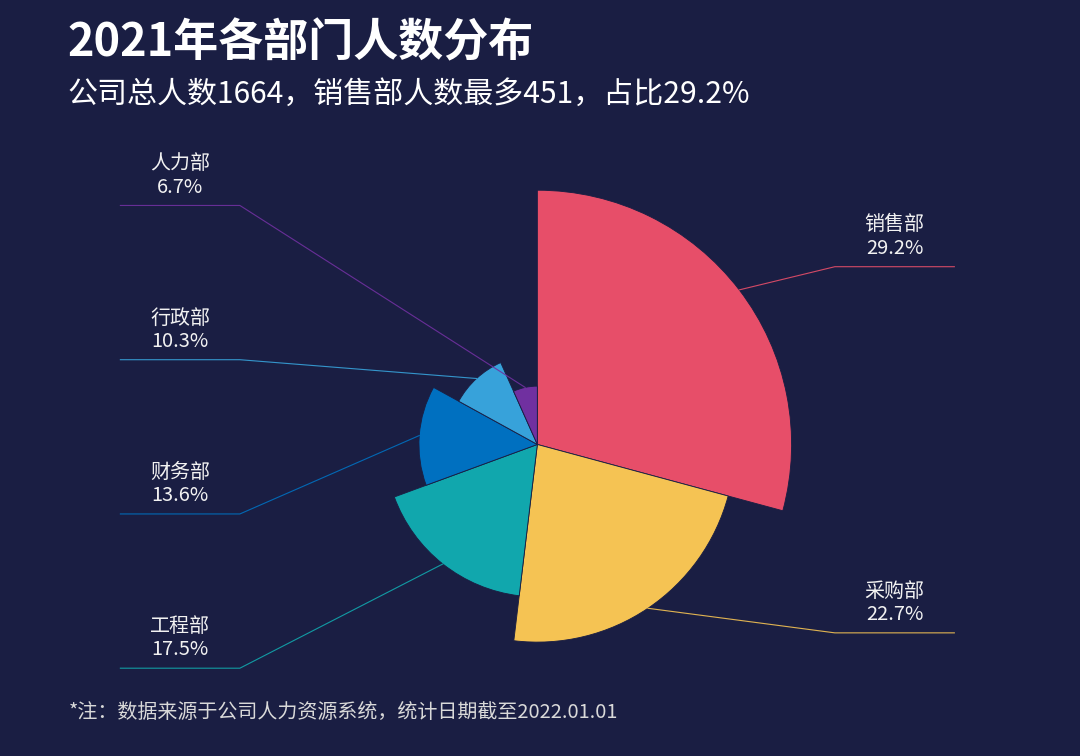

In [5]:
def chart_19(show=True):
    df=read_table(19,'B:C',6)
    fig,ax,root=canvas(19)
    rose(ax,df['部门'],numeric(df,'人数占比'),[PINK,'#F5C353','#11A7AD',BLUE,'#37A2DA','#7030A0'])
    template_text(fig,root)
    return finish(fig,19,'南丁格尔圆饼图',show)

fig=chart_19()
plt.close(fig)

## 20. 南丁格尔圆环图

数据源：后 15 图 Excel 的第 5 个工作表，区域 `B2:C6`（含表头）。

内孔按源 XML 的 60% 保留，各年龄段的扇区角度和外径由人数占比确定。多层圆环在不同办公软件中的显示可能不同。

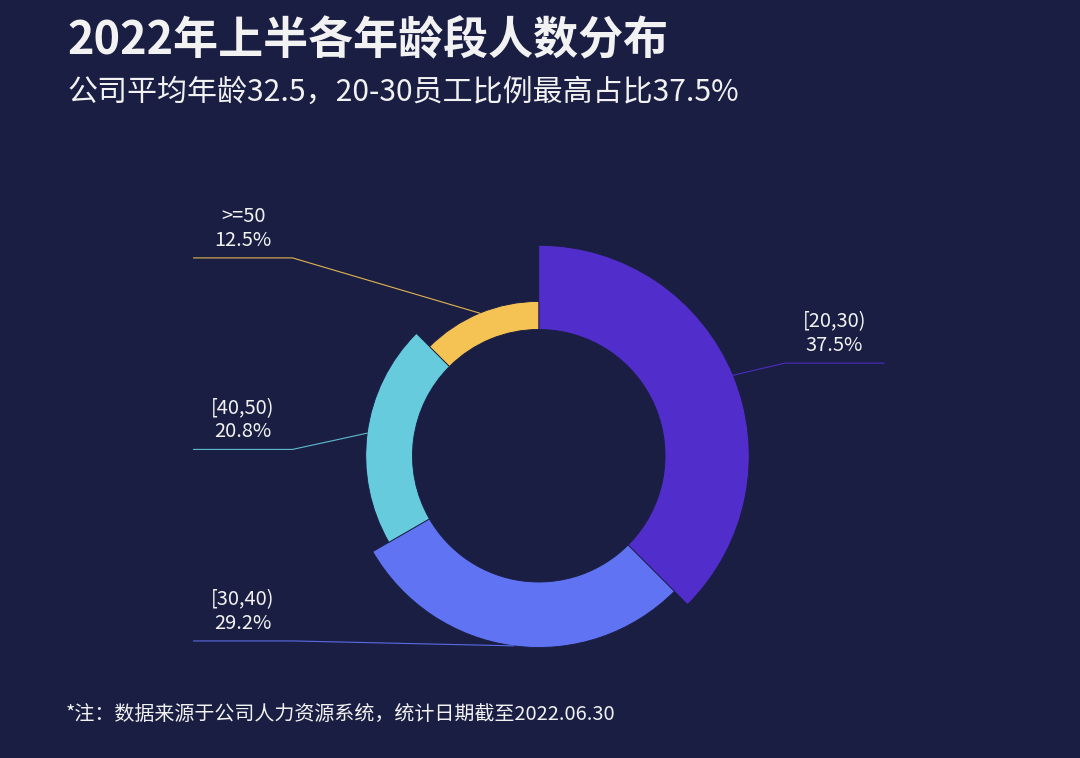

In [6]:
def chart_20(show=True):
    df=read_table(20,'B:C',4)
    fig,ax,root=canvas(20)
    # 保留源 XML 的 60% 内孔，按占比改变各扇区外径。
    rose(ax,df['年龄'],numeric(df,'人数占比'),['#512DCB','#6073F3','#66CBDD','#F5C353'],hole=.60)
    template_text(fig,root)
    return finish(fig,20,'南丁格尔圆环图',show)

fig=chart_20()
plt.close(fig)

## 21. 南丁格尔_PPT造型

数据源：后 15 图 Excel 的第 6 个工作表，区域 `B2:C8`（含表头）。

原工作表名为“20 南丁格尔（PPT）”，本项目按顺序编号为 21。读取本表原始数据；合计为 98.3%，保留余下空白角度，不自动归一化为 100%。

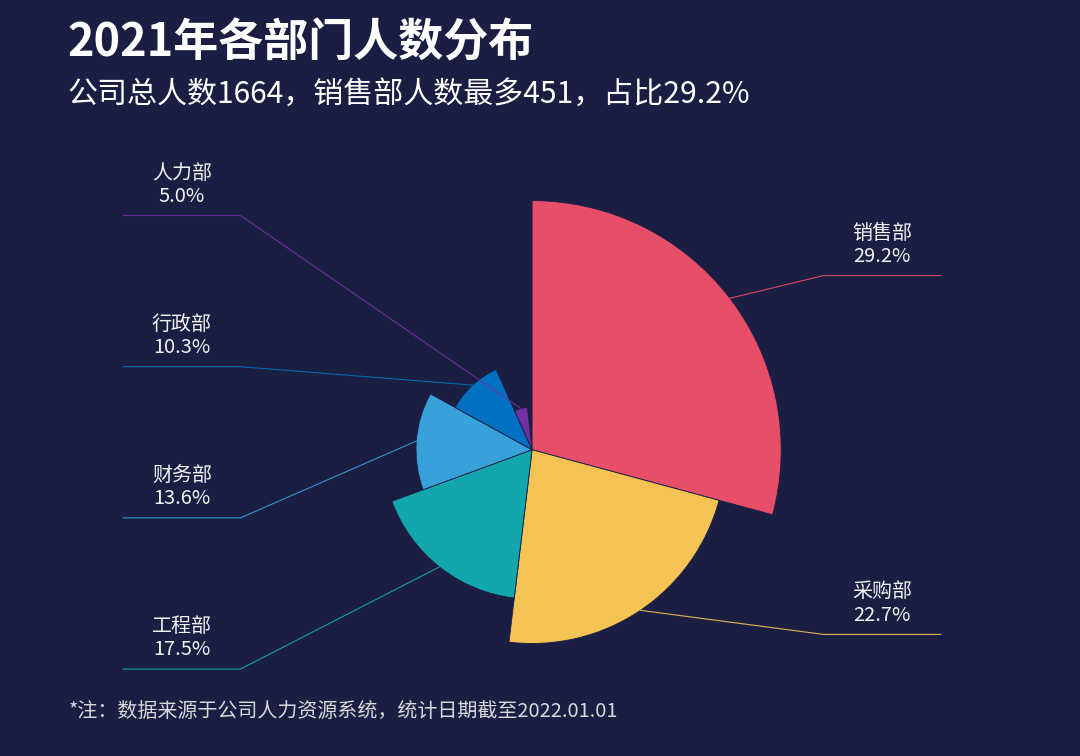

In [7]:
def chart_21(show=True):
    # 第 6 个工作表原名“20 南丁格尔（PPT）”；按顺序映射到 21。
    # 其独立表格最后一项为 5%，合计 98.3%；不使用透明辅助图表对第 19 表的引用。
    df=read_table(21,'B:C',6)
    fig,ax,root=canvas(21)
    rose(ax,df['部门'],numeric(df,'人数占比'),[PINK,'#F5C353','#11A7AD','#37A2DA',BLUE,'#7030A0'],
         normalize=False)
    _,title_root=template_xml(19)
    template_text(fig,title_root)
    return finish(fig,21,'南丁格尔_PPT造型',show)

fig=chart_21()
plt.close(fig)

## 22. 仪表盘图

数据源：后 15 图 Excel 的第 7 个工作表，区域 `H2:H3、B2:B23`（含表头）。

读取 H3 指针值与 B 列刻度。将 50—150 映射到 270° 表盘，以分段色带、刻度和白色指针重新绘制。越界数值仅对指针角度进行边界限制，数值仍显示实际输入。

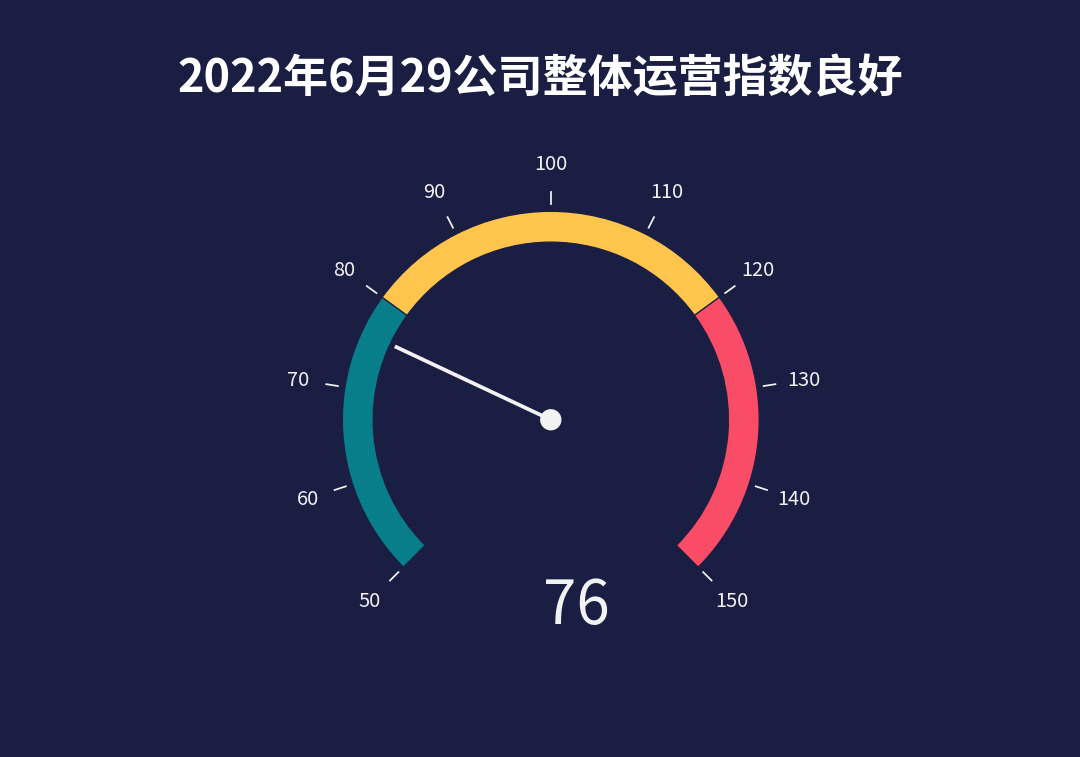

In [8]:
def chart_22(show=True):
    df=read_table(22,'H:H',1)
    value=float(df.loc[0,'指针数值'])
    scale=pd.read_excel(EXCEL_FILE,sheet_name=SHEET_NAMES[22],usecols='B',header=1,nrows=21,engine='openpyxl')
    marks=pd.to_numeric(scale.iloc[:,0],errors='raise').dropna().to_numpy(float)
    low,high=marks.min(),marks.max()
    if not np.isfinite(value) or high<=low:raise ValueError('无效的仪表盘读数或刻度。')
    clipped=np.clip(value,low,high)
    fig,ax,root=canvas(22)
    ax.set_position([.21,.12,.60,.65]);round_axes(ax)
    # 原始刻度范围 50—150，270° 刻度带：50—80 青绿、80—120 黄色、120—150 红色。
    for start,end,c in [(50,80,'#087E8B'),(80,120,'#FFC54D'),(120,150,'#F94C66')]:
        a=225-(start-low)/(high-low)*270;b=225-(end-low)/(high-low)*270
        ax.add_patch(Wedge((0,0),.88,b,a,width=.13,facecolor=c,edgecolor=BG,lw=.5))
    for v in marks:
        angle=np.deg2rad(225-(v-low)/(high-low)*270)
        ax.plot([.91*np.cos(angle),.96*np.cos(angle)],
                [.91*np.sin(angle),.96*np.sin(angle)],color=WHITE,lw=.7)
        ax.text(1.08*np.cos(angle),1.08*np.sin(angle),f'{v:g}',ha='center',va='center',
                color=WHITE,fontsize=8,clip_on=False)
    angle=np.deg2rad(225-(clipped-low)/(high-low)*270)
    ax.plot([0,.72*np.cos(angle)],[0,.72*np.sin(angle)],color=WHITE,lw=1.5,zorder=6)
    ax.add_patch(Circle((0,0),.045,facecolor=WHITE,edgecolor='none',zorder=7))
    template_text(fig,root,skip_exact=('76',))
    # 读数单独居中，避免 100—150 的三位数在源双位数文本框内自动换行。
    fig.text(.534,.20,f'{value:g}',ha='center',va='center',fontsize=24,color=WHITE)
    return finish(fig,22,'仪表盘图',show)

fig=chart_22()
plt.close(fig)

## 23. 柱形折线图

数据源：后 15 图 Excel 的第 8 个工作表，区域 `B2:D8`（含表头）。

蓝色柱表示销量，红色折线使用右轴。2017 年沿用原始同比，之后按相邻年份销量重算同比。

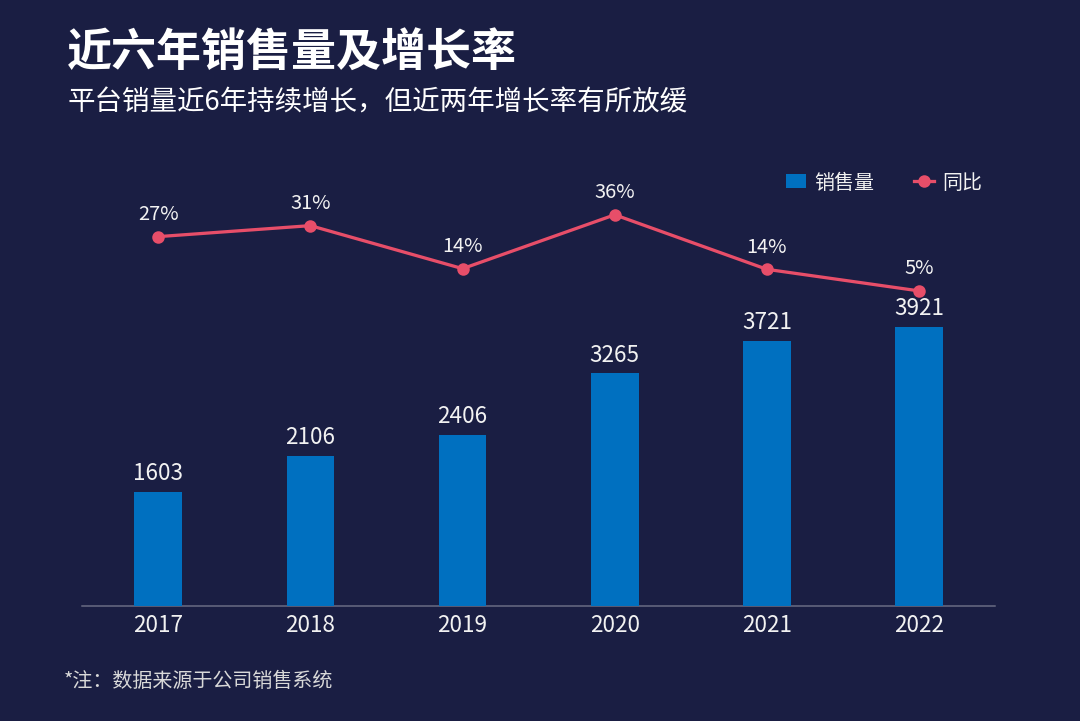

In [9]:
def chart_23(show=True):
    df=read_table(23,'B:D',6)
    sales=numeric(df,'销售量');growth=numeric(df,'同比')
    if (sales[:-1]==0).any():raise ValueError('上年销量为零，不能计算同比。')
    growth[1:]=sales[1:]/sales[:-1]-1
    x=np.arange(len(df));fig,ax,root=canvas(23)
    category_axis(ax,[str(int(v)) for v in df['年份']],6000,grid=False,ylabels=False,baseline=True)
    bar=ax.bar(x,sales,width=1/3.19,color=BLUE,zorder=3,label='销售量');value_labels(ax,x,sales)
    right=ax.twinx();right.set_ylim(-1.2,.5);right.set_yticks([])
    for spine in right.spines.values():spine.set_visible(False)
    line,=right.plot(x,growth,color=PINK,lw=1.3,marker='o',ms=4,label='同比')
    for xi,v in zip(x,growth):
        right.annotate(f'{v:.0%}',(xi,v),xytext=(0,5),textcoords='offset points',ha='center',
                       va='bottom',color=WHITE,fontsize=8)
    legend=fig.legend([bar,line],['销售量','同比'],bbox_to_anchor=(.926,.785),loc='upper right',
                      frameon=False,ncol=2,fontsize=8,handlelength=1,handletextpad=.4)
    for t in legend.get_texts():t.set_color(WHITE)
    template_text(fig,root)
    return finish(fig,23,'柱形折线图',show)

fig=chart_23()
plt.close(fig)

## 24. 目标柱形图

数据源：后 15 图 Excel 的第 9 个工作表，区域 `B2:D8`（含表头）。

外层空心柱表示目标销量，内层蓝色柱表示实际销量。使用同一数值尺度，不将实际与目标相加。

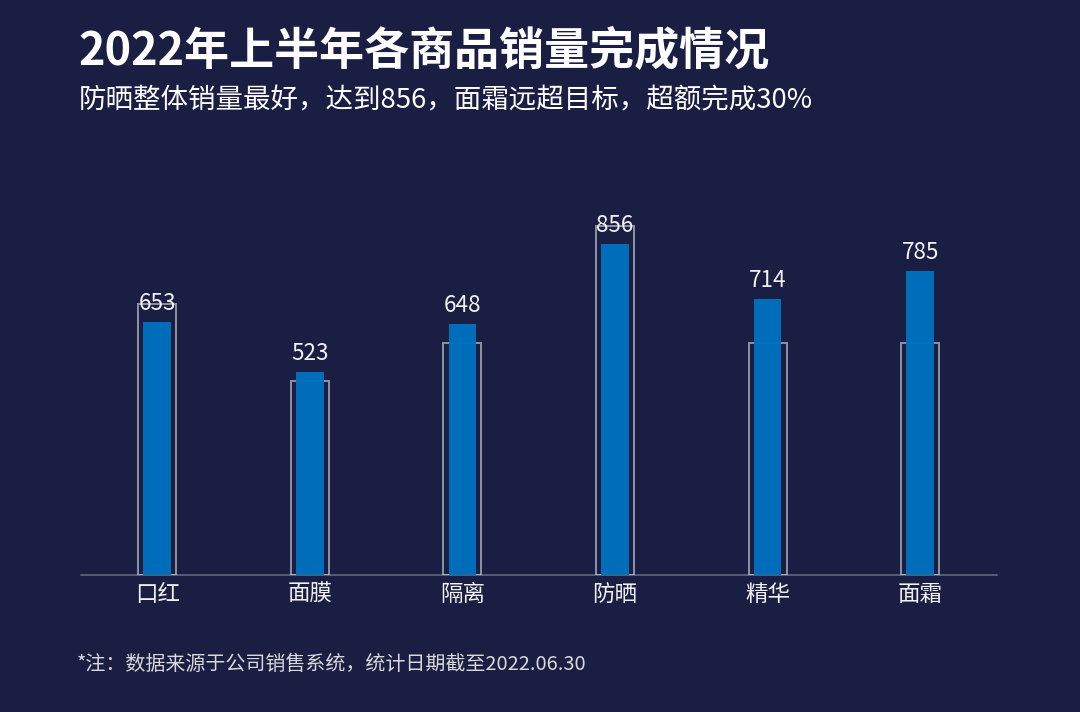

In [10]:
def chart_24(show=True):
    df=read_table(24,'B:D',6)
    actual,target=numeric(df,'实际销量'),numeric(df,'目标销量')
    x=np.arange(len(df));fig,ax,root=canvas(24)
    category_axis(ax,df['商品'].tolist(),1000,grid=False,ylabels=False,baseline=True)
    ax.bar(x,target,width=.25,facecolor='none',edgecolor=(1,1,1,.5),lw=.8,zorder=2)
    ax.bar(x,actual,width=1/5.5,color=BLUE,alpha=.97,zorder=3)
    value_labels(ax,x,actual)
    template_text(fig,root)
    return finish(fig,24,'目标柱形图',show)

fig=chart_24()
plt.close(fig)

## 25. 子弹图

数据源：后 15 图 Excel 的第 10 个工作表，区域 `B3:G9`（含表头）。

先堆积及格、良好、优秀三个背景区间，再覆盖实际销量窄柱，用黄色短横线标出目标值。表头在第 3 行。

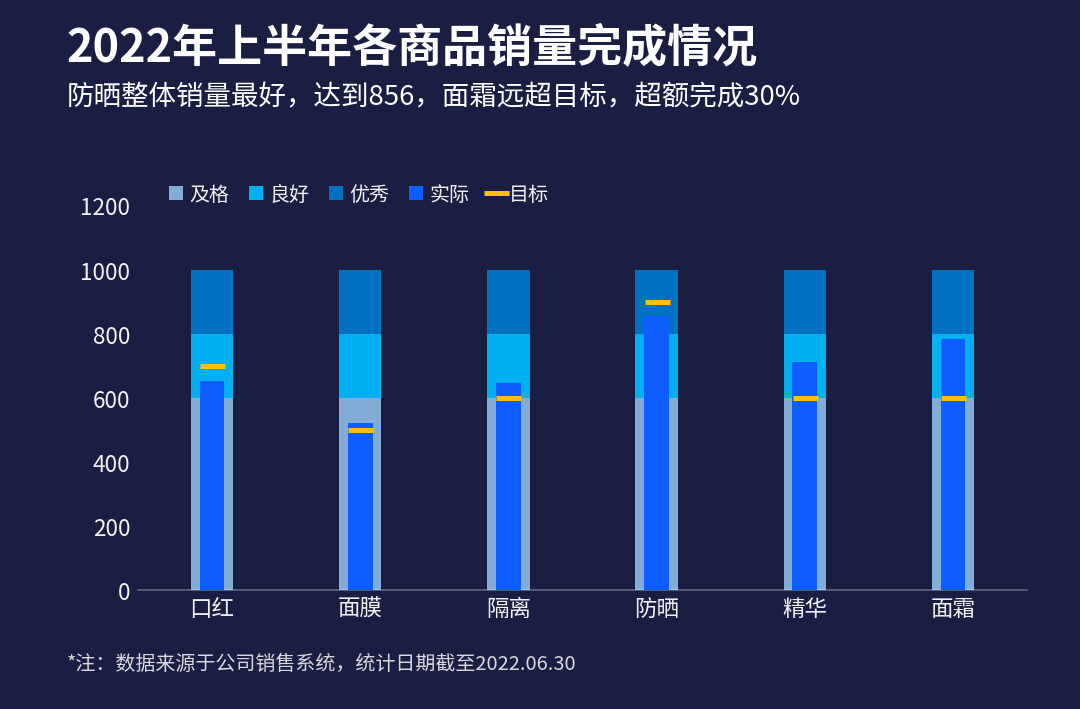

In [11]:
def chart_25(show=True):
    df=read_table(25,'B:G',6,header=2)
    actual,target=numeric(df,'实际'),numeric(df,'目标')
    passed,good,excellent=(numeric(df,c) for c in ['及格','良好','优秀'])
    x=np.arange(len(df));fig,ax,root=canvas(25)
    category_axis(ax,df['商品'].tolist(),1200,200,grid=False,baseline=True)
    handles=[]
    bottom=np.zeros(len(df))
    for values,c in zip([passed,good,excellent],[LIGHT_BLUE,'#00B0F0',BLUE]):
        handles.append(ax.bar(x,values,bottom=bottom,width=1/3.5,color=c,zorder=2))
        bottom+=values
    handles.append(ax.bar(x,actual,width=1/6,color='#0E5DFF',zorder=3))
    mark,=ax.plot(x,target,ls='none',marker='_',ms=10,mew=2,color='#FFC000',zorder=6)
    legend=fig.legend([*handles,mark],['及格','良好','优秀','实际','目标'],loc='upper left',
                      bbox_to_anchor=(.14,.765),frameon=False,ncol=5,fontsize=8,
                      handlelength=.7,handletextpad=.3,columnspacing=1)
    for t in legend.get_texts():t.set_color(WHITE)
    template_text(fig,root)
    return finish(fig,25,'子弹图',show)

fig=chart_25()
plt.close(fig)

## 26. 柱形圆

数据源：后 15 图 Excel 的第 11 个工作表，区域 `B2:E8`（含表头）。

粉色柱表示销量，上方蓝色圆的直径和内置百分比由同比去年列控制。不会把占位值 4500 当成同比标签。

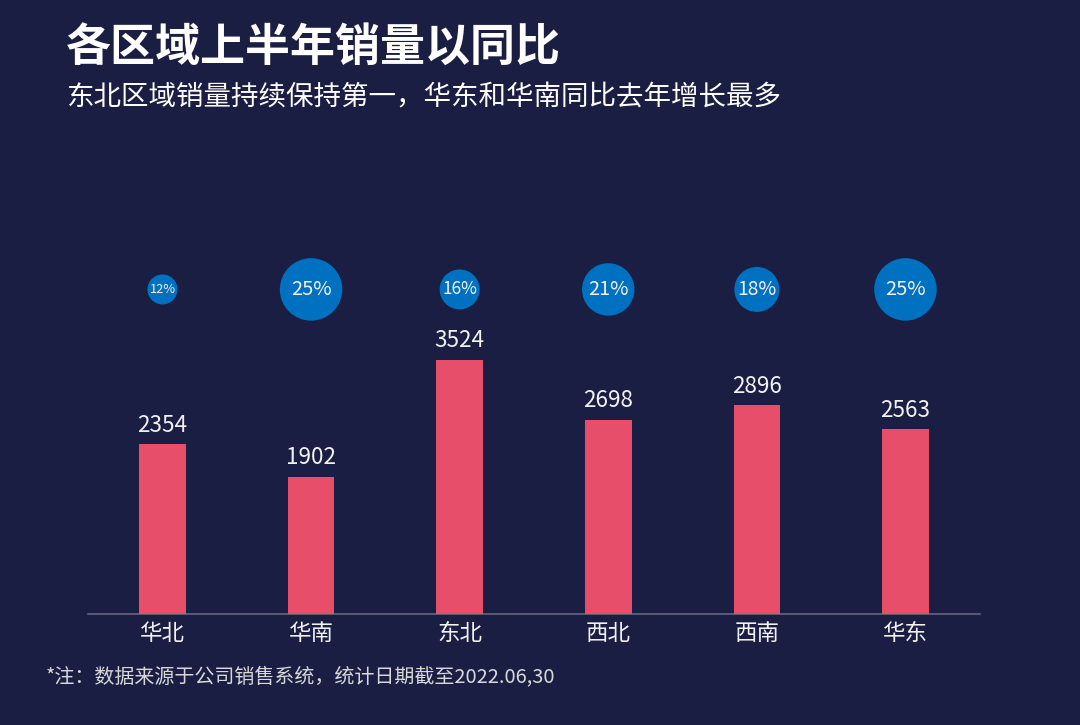

In [12]:
def chart_26(show=True):
    df=read_table(26,'B:E',6)
    sales,bubble,yoy=numeric(df,'销量'),numeric(df,'占位'),numeric(df,'同比去年')
    x=np.arange(len(df));fig,ax,root=canvas(26)
    category_axis(ax,df['区域'].tolist(),6000,grid=False,ylabels=False,baseline=True)
    ax.bar(x,sales,width=1/3.19,color=PINK,zorder=3);value_labels(ax,x,sales)
    sizes=np.maximum(8,np.abs(yoy)*100)
    ax.scatter(x,bubble,s=sizes**2,color=BLUE,edgecolors='none',zorder=4)
    for xi,yi,p,size in zip(x,bubble,yoy,sizes):
        ax.text(xi,yi,f'{p:.0%}',ha='center',va='center',fontsize=min(8,size*.43),color=WHITE,zorder=6)
    template_text(fig,root)
    return finish(fig,26,'柱形圆',show)

fig=chart_26()
plt.close(fig)

## 27. 簇状柱形折线图

数据源：后 15 图 Excel 的第 12 个工作表，区域 `B2:E8`（含表头）。

两组柱对比 2022 与 2021 销量，右轴黄色线读取原表同比率。原表同比为已提供的四舍五入数值，保留其口径。

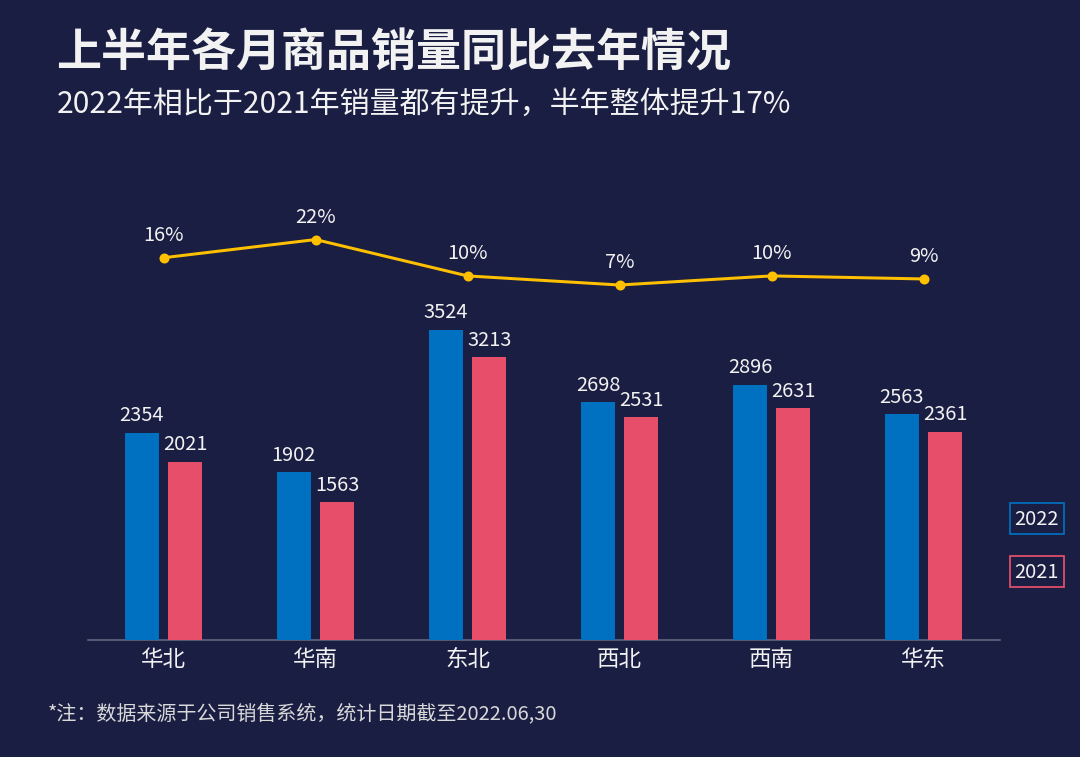

In [13]:
def chart_27(show=True):
    df=read_table(27,'B:E',6)
    now,old,growth=(numeric(df,c) for c in ['2022销量','2021销量','同比去年'])
    x=np.arange(len(df));fig,ax,root=canvas(27)
    category_axis(ax,df['区域'].tolist(),5000,grid=False,ylabels=False,baseline=True)
    width=1/(2+.27+2.19);shift=width*(1+.27)/2
    ax.bar(x-shift,now,width=width,color=BLUE,zorder=3)
    ax.bar(x+shift,old,width=width,color=PINK,zorder=3)
    value_labels(ax,x-shift,now,size=8);value_labels(ax,x+shift,old,size=8)
    right=ax.twinx();right.set_ylim(-1.1,.35);right.set_yticks([])
    for spine in right.spines.values():spine.set_visible(False)
    right.plot(x,growth,color='#FFC000',lw=1.2,marker='o',ms=3)
    for xi,v in zip(x,growth):
        right.annotate(f'{v:.0%}',(xi,v),xytext=(0,5),textcoords='offset points',ha='center',
                       va='bottom',color=WHITE,fontsize=8)
    template_text(fig,root,skip_exact=('2021','2022'))
    for label,c,y in [('2022',BLUE,.315),('2021',PINK,.245)]:
        fig.text(.960,y,label,ha='center',va='center',fontsize=8,color=WHITE,
                 bbox={'fc':'none','ec':c,'pad':2,'lw':.7})
    return finish(fig,27,'簇状柱形折线图',show)

fig=chart_27()
plt.close(fig)

## 28. 复合柱形图

数据源：后 15 图 Excel 的第 13 个工作表，区域 `B2:D17`（含表头）。

保留各季度之间的空行间距，按三个月销量重算季度合计。季度背景柱与月度窄柱共用零基线和数值尺度。

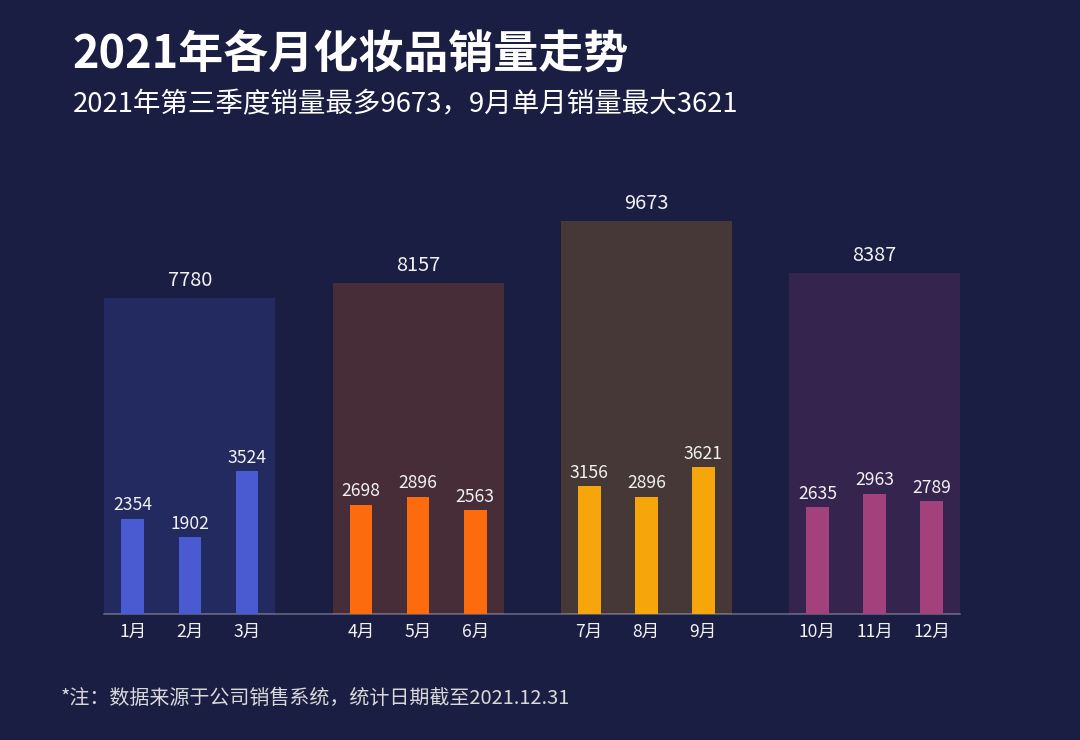

In [14]:
def chart_28(show=True):
    # 原表在各季度之间插入空行：保留这些间隔，不把月份挤到一起。
    df=pd.read_excel(EXCEL_FILE,sheet_name=SHEET_NAMES[28],usecols='B:D',header=1,nrows=15,engine='openpyxl')
    monthly=pd.to_numeric(df['月度销量'],errors='raise').to_numpy(float)
    labels=df['月份'].fillna('').tolist();x=np.arange(len(df))
    fig,ax,root=canvas(28)
    category_axis(ax,labels,12000,grid=False,ylabels=False,baseline=True)
    ax.tick_params(axis='x',labelsize=7)
    palette=['#4A5BD1','#FC6C0F','#F6A50B','#A2417B']
    for start,c in zip([0,4,8,12],palette):
        idx=np.arange(start,start+3)
        values=monthly[idx]
        if not np.isfinite(values).all():raise ValueError('季度包含缺失的月度销量。')
        total=values.sum()
        ax.bar(idx,np.full(3,total),width=1,color=c,alpha=.20,zorder=2)
        ax.bar(idx,values,width=.4,color=c,zorder=3)
        value_labels(ax,idx,values,size=7,offset=2)
        ax.annotate(f'{total:g}',(start+1,total),xytext=(0,3),textcoords='offset points',
                    ha='center',va='bottom',fontsize=8,color=WHITE)
    template_text(fig,root)
    return finish(fig,28,'复合柱形图',show)

fig=chart_28()
plt.close(fig)

## 29. 滑珠图

数据源：后 15 图 Excel 的第 14 个工作表，区域 `B2:E7`（含表头）。

灰色轨道表示 100%，蓝色长度表示完成率，滑珠直接放在相同比例的同一条轨道上，避免不同轴映射造成错位。

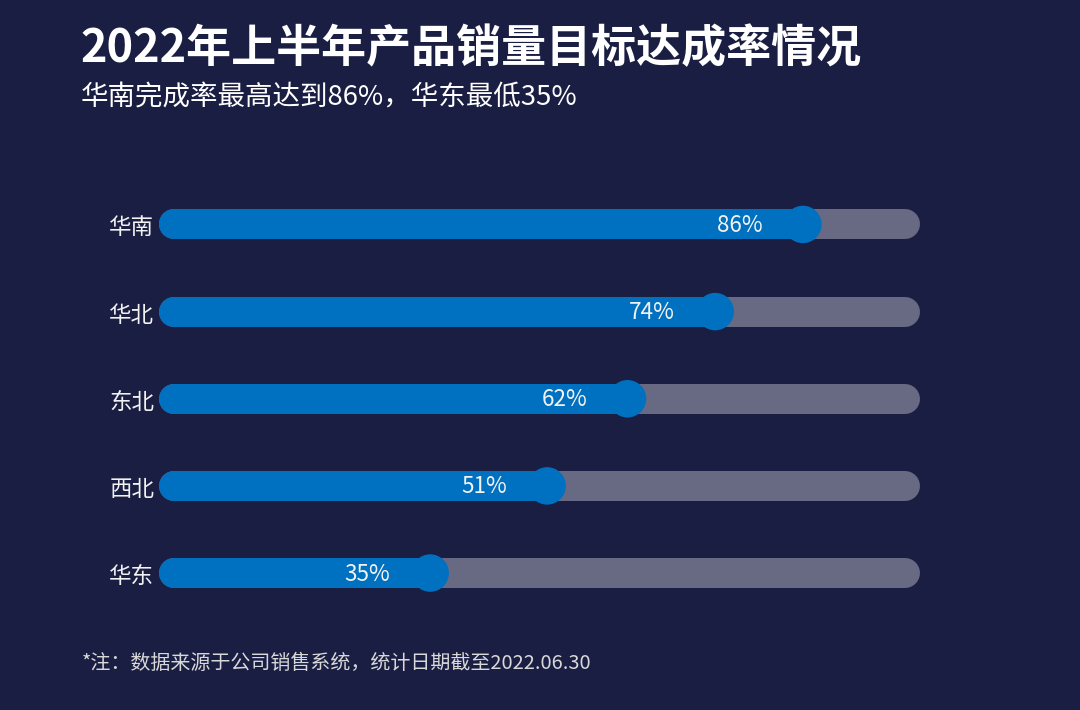

In [15]:
def chart_29(show=True):
    df=read_table(29,'B:E',5)
    values=numeric(df,'完成率');check_rates(values)
    fig,ax,root=canvas(29)
    ax.set_xlim(0,1);ax.set_ylim(-.5,len(df)-.5)
    ax.set_xticks([]);ax.set_yticks(np.arange(len(df)),df['区域']);ax.tick_params(axis='y',labelsize=9,pad=8)
    for j,p in enumerate(values):
        ax.plot([0,1],[j,j],lw=12,color=(1,1,1,.34),solid_capstyle='round',clip_on=False)
        ax.plot([0,p],[j,j],lw=12,color=BLUE,solid_capstyle='round',clip_on=False)
        ax.scatter([p],[j],s=15**2,color=BLUE,edgecolors='none',zorder=6)
        ax.text(max(.04,p-.055),j,f'{p:.0%}',ha='right',va='center',fontsize=9,color=WHITE,zorder=7)
    template_text(fig,root)
    return finish(fig,29,'滑珠图',show)

fig=chart_29()
plt.close(fig)

## 30. 对比滑珠图

数据源：后 15 图 Excel 的第 15 个工作表，区域 `B3:F8`（含表头）。

同一条轨道对比两年完成率，2022 年为蓝色滑珠，2021 年为灰色滑珠，按原表区域顺序显示。表头在第 3 行。

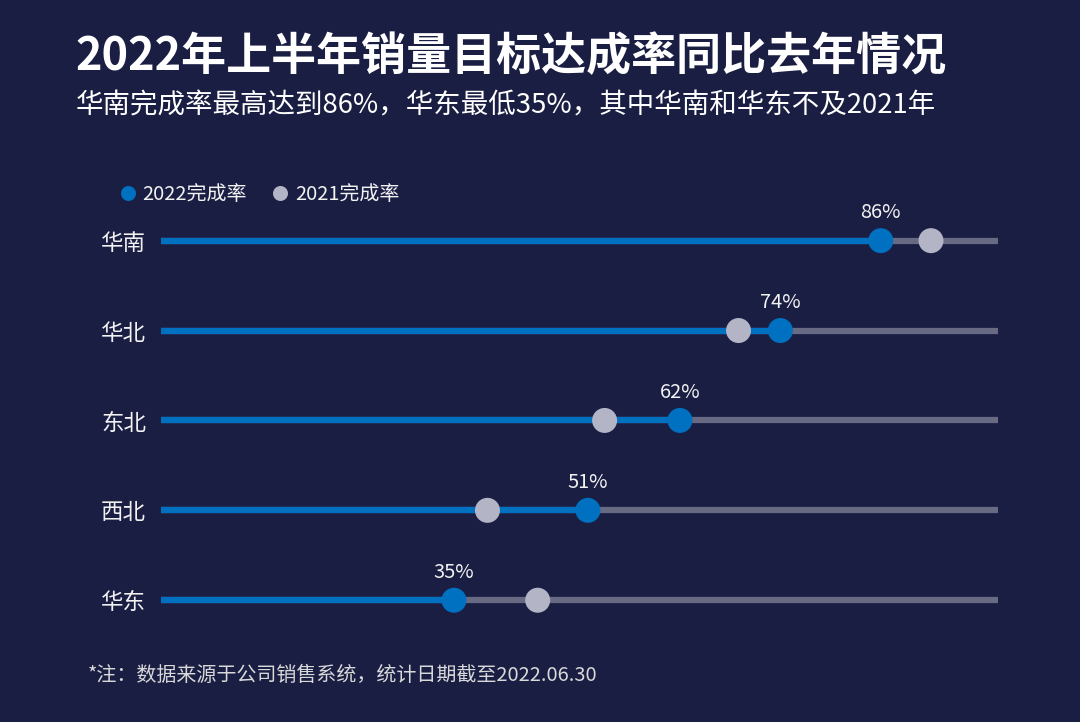

In [16]:
def chart_30(show=True):
    df=read_table(30,'B:F',5,header=2)
    now,old=numeric(df,'2022完成率'),numeric(df,'2021完成率')
    check_rates(now);check_rates(old)
    fig,ax,root=canvas(30)
    ax.set_xlim(0,1);ax.set_ylim(-.5,len(df)-.5)
    ax.set_xticks([]);ax.set_yticks(np.arange(len(df)),df['区域']);ax.tick_params(axis='y',labelsize=9,pad=6)
    for j,(a,b) in enumerate(zip(now,old)):
        ax.plot([0,1],[j,j],color=(1,1,1,.34),lw=2.5,zorder=2)
        ax.plot([0,a],[j,j],color=BLUE,lw=2.5,zorder=3)
        ax.scatter([b],[j],s=10**2,color='#B3B4C5',edgecolors='none',zorder=5)
        ax.scatter([a],[j],s=10**2,color=BLUE,edgecolors='none',zorder=6)
        ax.annotate(f'{a:.0%}',(a,j),xytext=(0,7),textcoords='offset points',
                    ha='center',va='bottom',fontsize=8,color=WHITE,zorder=7)
    template_text(fig,root,skip_text=('完率',))
    legend=fig.legend([Line2D([],[],ls='none',marker='o',color=BLUE,ms=5),
                       Line2D([],[],ls='none',marker='o',color='#B3B4C5',ms=5)],
                      ['2022完成率','2021完成率'],loc='upper left',bbox_to_anchor=(.095,.77),
                      frameon=False,ncol=2,fontsize=8,handlelength=.7,handletextpad=.4,columnspacing=1.3)
    for t in legend.get_texts():t.set_color(WHITE)
    return finish(fig,30,'对比滑珠图',show)

fig=chart_30()
plt.close(fig)

## 完成

已生成后 15 张图。也可在项目根目录运行 `python scripts/render_all.py` 批量生成，或添加 `--chart 16` 等参数单独生成。